# Does a Hit Last? Early Signals of Chart Longevity on the Billboard Hot 100
**INFO 2950, Phase 3 (graded draft)**

Data and code: https://github.com/harrylin1015/info2950-chart-longevity

**How to read this report.** Sections follow the rubric's order. Every statistical term is explained in plain words in the box "How to read our statistics" at the start of Data analysis. A list of what we changed after Phase 2 feedback is near the end.

## Introduction

### Why this matters
A song's first week on the Billboard Hot 100 can be misleading. Fans can stream a new song thousands of times on release day, so a song can debut high and be gone a few weeks later, while another debuts quietly and stays for half a year. Record labels, playlist editors, and artists decide where to spend money and attention in the first week or two, long before anyone knows how long a song will last.

Earlier research modeled how long Hot 100 songs survive (Bradlow and Fader, 2001), found that songs usually chart in one unbroken run (Pessa et al., 2026), and showed that hits are hard to predict ahead of time (Salganik, Dodds and Watts, 2006). We ask a narrower, practical question: once a song has debuted, how much do its first two weeks tell us?

### Key terms
- **Billboard Hot 100**: the weekly list of the 100 most popular songs in the US, based on streams, sales, and radio play.
- **Run length**: how many weeks a song spends on the Hot 100. A **long run** is 20 weeks or more.
- **Recurrent rule**: Billboard removes older songs that have slipped down the chart. A song below No. 50 is removed after 20 weeks, so 20 weeks is a natural line between a long run and a short one. Since October 2025, stricter cutoffs also apply after 26, 52, and 78 weeks (Thompson, 2025).
- **Album track**: a song whose artist put 3 or more songs on the Hot 100 in the same week, which usually means an album came out.
- **Established artist**: the artist had a Hot 100 song in the 3 years before this one.
- **Spotify Top 200**: Spotify's weekly list of the 200 most-streamed songs in the US, with stream counts.
- **Front-loading (F)**: the share of a song's first two weeks of Spotify streams that came in week 1. F = 0.5 means the two weeks were equal; F = 0.7 means 70% came in week 1.
- **Early signals**: things we know about a song within its first two weeks, before anyone knows how long it will last.
- **Matched song**: a Billboard song we also found on Spotify's chart, using its title and first artist.
- **EDA**: exploratory data analysis, our first look at the data with summary numbers and charts.

### Research question
**Among songs that debuted on the Hot 100 between January 2022 and October 2025, which early signals predict whether a song lasts 20 weeks or more?**

We study five early signals: debut rank, how far the song moves in week 2, whether it came out with an album, whether the artist is established, and how its Spotify streams changed from week 1 to week 2.

**Which years we use.** Billboard: every weekly chart from Jan 1, 2022 to Oct 17, 2026. Spotify: every weekly chart from Jan 6, 2022 to Oct 29, 2026, covering the same weeks. Our tests use songs that debuted by Oct 18, 2025, so every song has had at least a year to finish its run.

We test three hypotheses:
1. Songs that fall further in week 2 are less likely to last 20 weeks.
2. Songs by established artists last fewer weeks than songs by newer artists that debut at the same rank.
3. Songs whose Spotify streams are packed into week 1 last fewer weeks.

### Summary of findings
- **Week 2 is the clearest signal.** A non-album song that debuts at No. 40 and holds its rank has a 56% chance of lasting 20 weeks. If it falls 20 spots, the chance drops to 26%.
- **Album tracks fade faster.** An album track in the same spot that holds its rank has a 31% chance.
- **Established artists' songs last about a third fewer weeks (34% fewer)** than newer artists' songs that debut at the same rank. The gap comes from songs that debut outside the top 20.
- **Songs whose streams spike in week 1 leave sooner.** A song whose early streams split 70/30 between weeks 1 and 2 lasts about half as many weeks as a song split 60/40 with the same total streams.

## Data description and cleaning
We describe our data using the "Datasheets for Datasets" questions (Gebru et al., 2021).

**Where the data comes from.**
- **Billboard Hot 100.** We use `hot-100-current.csv` (McDonald, 2026), a public archive kept by Christian McDonald, a journalism professor at UT Austin. A script copies the chart from billboard.com (Billboard, 2022 to 2026) every week. We downloaded it on Oct 14, 2026. The archive's older years were pieced together from other sources, so we only use charts from 2022 on, which were copied straight from billboard.com.
- **Spotify US Top 200.** Weekly CSV files from Spotify's official chart site, charts.spotify.com (Spotify, 2022 to 2026): one file per week, all 252 weeks from Jan 6, 2022 to Oct 29, 2026. We downloaded the first 23 weeks by hand. One of us downloaded the rest with a short browser script that opened each week's chart page while signed in and clicked its download button.
- **Why these sources.** The scraping tools we first planned to use (`billboard.py` and `fycharts`) no longer work, and we avoided Kaggle datasets because we could not check where their data came from.

**What the rows and columns are.**
- **Billboard file:** one row per song per week, with its rank, last week's rank, peak, and weeks on the chart so far. From 2022 to Oct 17, 2026 there are 25,100 rows: 251 charts of exactly 100 songs.
- **Spotify files:** one row per song per week, with its rank, artist, title, and streams. 252 files and 50,399 rows.
- **Our cleaned table (`analysis_ready.csv`):** one row per song, with 3,117 songs and 44 columns. The main columns are the outcome (`weeks_on_chart_total`, `long_run`), the early signals (`debut_rank`, `week2_change`, `album_track`, `established`, `front_load`, and early stream counts), and flags that say which songs each test uses (`new_entry`, `followed_1yr`). We keep each song's peak rank only to describe it, never as a predictor, since a peak is only known after the run ends.

**Why it was created and who paid for it.** We built it for this class project, and no one funded it. Billboard sells its chart as a product, using data licensed from Luminate. Spotify publishes its charts to show what people stream. The Billboard archive is kept for teaching data journalism.

**What shaped what was recorded.**
- Both charts list only top songs (100 and 200), so smaller songs never appear.
- Billboard's recurrent rule removes songs before their popularity fully fades, so many runs end at exactly 20 weeks (153, against 25 at 19 weeks). The rule cannot remove a song before 20 weeks, so whether a song reaches 20 weeks is up to listeners. That is why 20 weeks is our cutoff.
- Billboard dates each chart 9 days after the end of the week it measures. That is why 86% of matched songs (1,894 of 2,194) appear on Billboard exactly 9 days after their first Spotify week.

**What is missing.** Week-2 rank is missing for the 42% of songs we follow that were not on the chart in week 2 (most charted for only one week). Spotify columns are missing for the 24.5% of Billboard debuts with no Spotify match, mostly small songs that never made Spotify's Top 200.

**Did people know their data was collected?** Partly. The charts count millions of people's streams, purchases, and radio plays. Spotify users agree to terms that say their listening is recorded. Buyers and radio listeners are counted by Luminate and likely do not know. Only song totals are published, so no person can be identified.

**Is the data trustworthy?** We checked the Billboard archive against itself. Every chart since 2022 has exactly 100 songs with no shared ranks, and in all 21,061 cases where a song appears two weeks in a row, its "last week" rank matches. We found and fixed three problems: Billboard sometimes renames an artist credit partway through a run (which split 60 songs in two), the weeks-on-chart count breaks in the last three charts, and the archive uses 0 for "not on last week's chart." The Spotify files come straight from Spotify, and the 23 weeks we downloaded twice (by hand and by script) match in every rank and stream count.

**Where to find the raw data.** The original Billboard archive is at https://github.com/utdata/rwd-billboard-data. Our copies of the Billboard file and all 252 Spotify files are at https://github.com/harrylin1015/info2950-chart-longevity/tree/main/Data

**Credit.** We thank Christian McDonald for keeping the Billboard archive public. The chart data belongs to Billboard (with Luminate) and Spotify.

### Data cleaning
All cleaning happens in a separate notebook, **`01_data_cleaning.ipynb`** (https://github.com/harrylin1015/info2950-chart-longevity/blob/main/01_data_cleaning.ipynb), which explains every step. In short, it:
1. Renames columns, removes 13 duplicate rows (all from 1990), and keeps Billboard charts from 2022 on.
2. Gives each song an ID made from its title and first artist, so a renamed credit does not split one song in two, and collapses the data to one row per song.
3. Matches Spotify songs to Billboard songs by a cleaned title and first artist. The match handles accents, curly apostrophes, and different ways of writing "featuring," and only 22 of 868 top-40 debuts are left unmatched.
4. Computes each song's early signals and flags, including its Spotify streams in weeks 1 and 2 and F.
5. Saves the cleaned tables to `Data/cleaned/` on GitHub, which this notebook loads. This notebook does no cleaning of its own.

We used pandas (McKinney, 2010), NumPy (Harris et al., 2020), statsmodels (Seabold & Perktold, 2010), SciPy (Virtanen et al., 2020), matplotlib (Hunter, 2007), and seaborn (Waskom, 2021).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.duration.hazard_regression import PHReg
from statsmodels.duration.survfunc import SurvfuncRight
from scipy.stats import rankdata
from matplotlib.ticker import PercentFormatter

# Cleaned files exported by 01_data_cleaning.ipynb
CLEAN_FOLDER = "https://raw.githubusercontent.com/harrylin1015/info2950-chart-longevity/main/Data/cleaned/"

df = pd.read_csv(CLEAN_FOLDER + "analysis_ready.csv",
                 parse_dates=["first_week", "last_week", "spotify_first_date"])
bb = pd.read_csv(CLEAN_FOLDER + "billboard_weekly_2022on.csv", parse_dates=["week"])

sns.set_theme(style="whitegrid")
BLUE, ORANGE, GREEN = "#2a78d6", "#eb6834", "#1baf7a"
pd.set_option("display.width", 120)

def show_fit(fit, terms, odds=False):
    """Compact table for the inputs we care about: estimate, 95% CI, and p-value."""
    ci = fit.conf_int()
    t = pd.DataFrame({"estimate": fit.params[terms], "95% CI low": ci.loc[terms, 0],
                      "95% CI high": ci.loc[terms, 1]})
    if odds:  # logistic regression: show odds ratios
        t = np.exp(t).rename(columns={"estimate": "odds ratio"})
    t = t.round(3)
    t["p-value"] = [("< 0.001" if p < 0.001 else f"{p:.3f}") for p in fit.pvalues[terms]]
    return t

# Songs that debuted at least 52 weeks before the latest chart (used by Hypotheses 1 and 2)
followed = df[df["followed_1yr"]].copy()

latest_week = df["last_week"].max()
print("songs:", len(df), "| debuts we saw:", df["new_entry"].sum(), "| followed at least a year:", df["followed_1yr"].sum(),
      "| latest chart:", latest_week.date())

songs: 3117 | debuts we saw: 2924 | followed at least a year: 2350 | latest chart: 2026-10-17


Five random debuts from the cleaned table:

In [2]:
# A few rows of the cleaned data we analyze (5 random debuts)
display(df.loc[df["new_entry"], ["title", "artist", "first_week", "debut_rank", "week2_change", "album_track",
                                 "established", "weeks_on_chart_total", "long_run"]].sample(5, random_state=1))

,title,artist,first_week,debut_rank,week2_change,album_track,established,weeks_on_chart_total,long_run
264,BBW,Drake,2026-05-30,74,NaN,True,1.0,1,False
748,Dos Dias,Tito Double P & Peso Pluma,2024-09-21,84,6.0,False,0.0,20,True
662,Dejame Entrar,Rauw Alejandro,2024-11-30,96,NaN,True,1.0,1,False
731,Don't Say You Love Me,Jin,2025-05-31,90,NaN,False,1.0,1,False
115,All Of You,"Stephanie Beatriz, Olga Merediz, John Leguizam...",2022-01-29,94,12.0,False,1.0,7,False


### Figures from our exploratory analysis
Two figures from our EDA explain our outcome and our first hypothesis.

**Figure 1. How long do songs stay on the chart?** Total weeks for every finished run. Dashed lines mark Billboard's removal points.

finished runs: 2825 | median 2 weeks | mean 7.6 | longest 112 | skew 2.60
1 week only: 38.0% | 4 weeks or less: 64.0% | 20+ weeks: 15.8%
runs ending at 19 / 20 / 21 weeks: 25 153 29


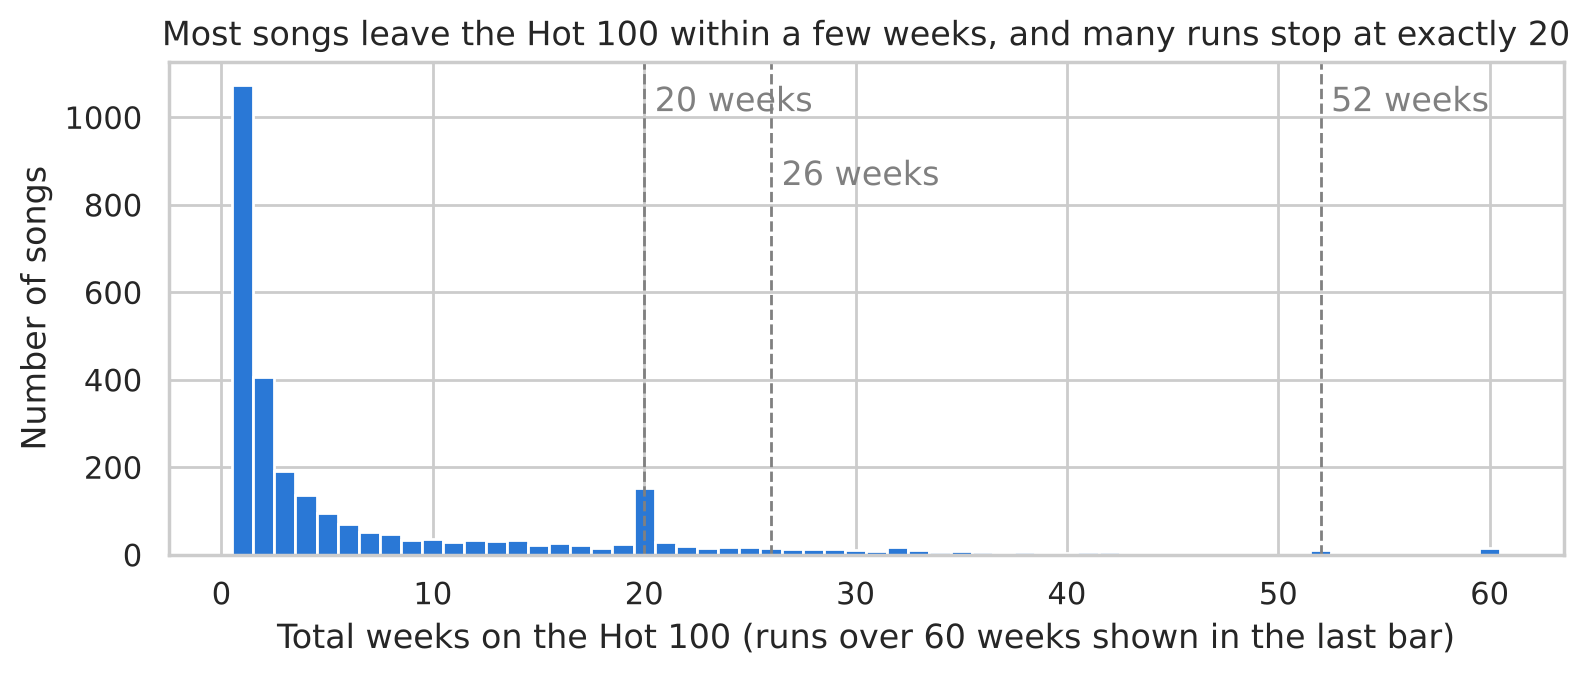

In [3]:
# Outcome: total weeks on the chart for finished runs
weeks = df.loc[df["complete_run"], "weeks_on_chart_total"]
print(f"finished runs: {len(weeks)} | median {weeks.median():.0f} weeks | mean {weeks.mean():.1f} | longest {weeks.max()}"
      f" | skew {weeks.skew():.2f}")
print(f"1 week only: {(weeks == 1).mean():.1%} | 4 weeks or less: {(weeks <= 4).mean():.1%} | 20+ weeks: {(weeks >= 20).mean():.1%}")
print("runs ending at 19 / 20 / 21 weeks:", (weeks == 19).sum(), (weeks == 20).sum(), (weeks == 21).sum())

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(weeks.clip(upper=60), bins=np.arange(0.5, 61.5, 1), color=BLUE, edgecolor="white")
for cutoff, height in [(20, 0.9), (26, 0.75), (52, 0.9)]:  # Billboard removal rules
    ax.axvline(cutoff, color="gray", linestyle="--", linewidth=1)
    ax.text(cutoff + 0.5, ax.get_ylim()[1] * height, f"{cutoff} weeks", color="gray")
ax.set_xlabel("Total weeks on the Hot 100 (runs over 60 weeks shown in the last bar)")
ax.set_ylabel("Number of songs")
ax.set_title("Most songs leave the Hot 100 within a few weeks, and many runs stop at exactly 20")
plt.show()

Most songs leave fast. The middle song lasts **2 weeks**, 38% last a single week, and only 15.8% reach 20 weeks, while a few last over 100 weeks. The spike at exactly 20 weeks (153 runs) comes from Billboard's removal rule.

A few very long runs would dominate a model of raw weeks, so we use two outcomes: whether a song reaches 20 weeks (yes or no), and log(weeks), a scale where going from 1 to 2 weeks counts as much as going from 10 to 20.

**Figure 2. How do long and short runs differ in their first two weeks?** We group songs by run length and compare debut rank and week-2 movement. In a box plot, the box holds the middle half of the songs and the line inside it is the median. One-week songs have no week-2 rank, so they appear only on the left.

,songs,median_debut_rank,songs_on_chart_in_week_2,median_week2_change
run_length,,,,
1 week,852,74.0,0,NaN
2-4 weeks,587,44.0,538,-35.0
5-19 weeks,502,54.0,456,-7.0
20+ weeks,409,49.0,370,-0.5


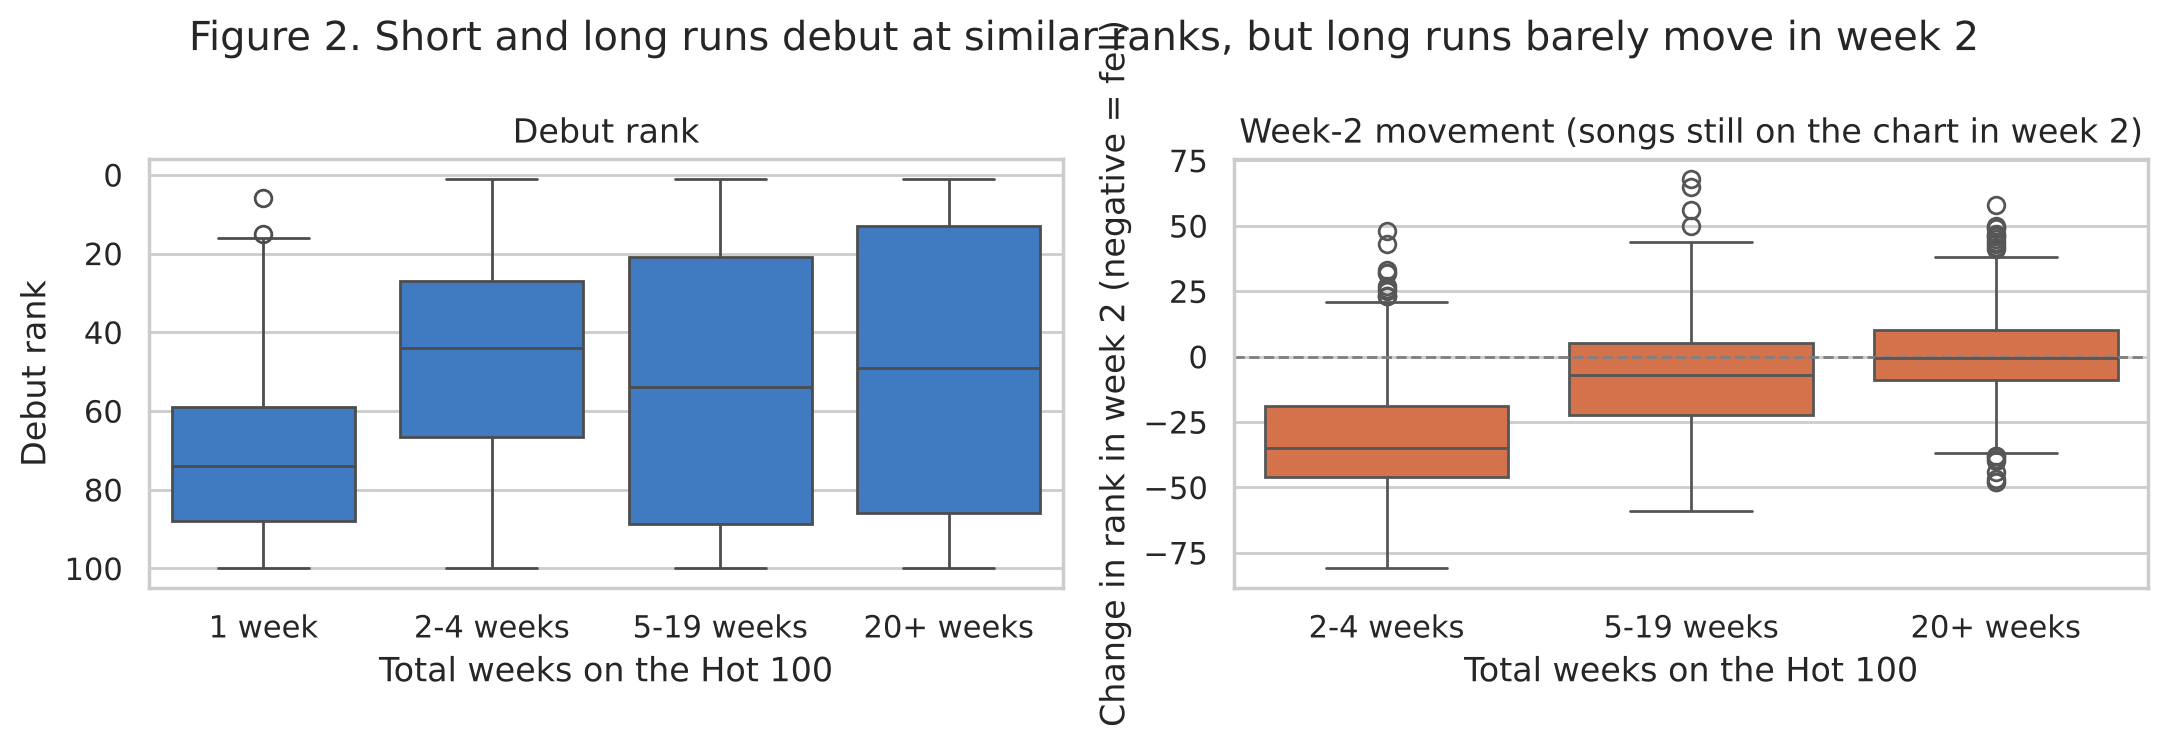

In [4]:
# Figure 2: debut rank and week-2 movement for each run length (songs followed at least a year)
fig2 = followed.copy()
order = ["1 week", "2-4 weeks", "5-19 weeks", "20+ weeks"]
fig2["run_length"] = pd.cut(fig2["weeks_on_chart_total"], bins=[0, 1, 4, 19, 1000], labels=order)
display(fig2.groupby("run_length", observed=True)
            .agg(songs=("debut_rank", "size"), median_debut_rank=("debut_rank", "median"),
                 songs_on_chart_in_week_2=("week2_change", "count"), median_week2_change=("week2_change", "median")))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
sns.boxplot(data=fig2, x="run_length", y="debut_rank", order=order, color=BLUE, ax=axes[0])
axes[0].invert_yaxis()  # No. 1 at the top
axes[0].set_xlabel("Total weeks on the Hot 100")
axes[0].set_ylabel("Debut rank")
axes[0].set_title("Debut rank")
sns.boxplot(data=fig2.dropna(subset=["week2_change"]), x="run_length", y="week2_change", order=order[1:],
            color=ORANGE, ax=axes[1])
axes[1].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[1].set_xlabel("Total weeks on the Hot 100")
axes[1].set_ylabel("Change in rank in week 2 (negative = fell)")
axes[1].set_title("Week-2 movement (songs still on the chart in week 2)")
fig.suptitle("Figure 2. Short and long runs debut at similar ranks, but long runs barely move in week 2")
plt.tight_layout()
plt.show()

Debut rank barely separates songs that last 2 to 4 weeks (median debut No. 44) from songs that last 20+ weeks (No. 49). Week 2 does: short runs fall a median of 35 spots, while long runs barely move. One-week songs debut much lower (No. 74). This is why the week-2 drop is our first hypothesis.

## Preregistration statements
*We wrote these before fitting any models.*

### Statement 1
**Hypothesis 1:** Among songs still on the Hot 100 in their second week, a bigger week-2 drop is associated with a lower chance of lasting 20 or more weeks, holding debut rank and album release constant.

*Why we expect this:* a debut week includes a burst from a song's biggest fans. If casual listeners don't pick it up, the song falls hard in week 2. In our EDA, short and long runs debuted at about the same rank but split apart in week 2 (Figure 2).

*Analysis:* for songs followed at least a year that are still on the chart in week 2, a logistic regression predicts `long_run` (20+ weeks) from `week2_change` (positive = climbed), `debut_rank`, and `album_track`. We test whether the `week2_change` coefficient is above 0. As a second check, a linear regression predicts log(weeks) from the same inputs.

### Statement 2
**Hypothesis 2:** Being an established artist is associated with fewer weeks on the Hot 100, holding debut rank and album release constant.

*Why we expect this:* established artists have big fan bases that stream a new song right away, which pushes it to a high debut that then fades. A newer artist who debuts at the same rank likely got there through wider interest, which lasts longer. In our EDA, 28% of non-album songs by new artists reached 20 weeks, against 20% for artists with 10 or more earlier hits.

*Analysis:* `established` = 1 if the lead artist had a Hot 100 song in the 3 years before the debut (we use pre-2022 charts only for this look-back). For songs followed at least a year, a linear regression predicts log(weeks) from `established`, `debut_rank`, and `album_track`. We test whether the `established` coefficient is below 0. We also add an interaction with a top-20 debut, to see whether the effect is strongest for top-20 debuts.

### Statement 3
**Hypothesis 3:** The share of a song's first two weeks of Spotify streams that came in week 1 (F) is associated with fewer weeks on the Hot 100, holding total early streams constant.

*Why we expect this:* a song streamed mostly in week 1 was likely driven by fans checking out a new release, while a song whose streams hold up is spreading to casual listeners and playlists. In our EDA, songs with more first-week streams lasted longer (a rank correlation of 0.49, where 0 means no link and 1 a perfect match), but total streams alone cannot tell a fan spike from a song that keeps growing.

*Analysis:* F = week-1 streams ÷ (week-1 + week-2 streams). A linear regression predicts log(weeks) from F and log(total early streams). We test whether the F coefficient is below 0. We planned to use Spotify charts from October 2024 to October 2025. A song that falls out of the Top 200 in week 2 counts as 0 streams that week; as a check, we replace that 0 with the No. 200 song's streams.

### Related work
- Bradlow and Fader (2001) modeled how long Hot 100 songs last, the same framing we use. Pessa et al. (2026) find that attention to songs fades fast, which suggests the first weeks carry information.
- Studies of cultural markets find that early success depends partly on social influence and is hard to predict from the song alone (Salganik, Dodds and Watts, 2006; Askin and Mauskapf, 2017), which makes who the artist is a plausible signal.
- Billboard's 2025 rule change (Thompson, 2025) responded to songs lingering on the chart for months, which shows that how long listening holds up shapes a chart run.

**Why the answers matter either way.** If these signals work, labels and playlist editors get a useful warning one or two weeks after release. If they don't, early promotion decisions are mostly guesswork.

### How we test significance
Each test is one-sided: it only counts evidence in the direction we predicted. Because we test three hypotheses, we also use a stricter cutoff of 0.05 / 3 ≈ 0.017 (a Bonferroni correction). Linear regressions use robust (HC1) standard errors, and we rerun every main test with clustered standard errors.

### Changes to our plan
- **Week 2 (Statement 1).** "Week 2" now means the chart exactly one week after the debut. Our first code used a song's second week on the chart, which for about 130 songs was a comeback weeks later.
- **Established artists (Statement 2).** Our TA felt our definition is too loose. We keep it for the main test and add two stricter definitions as a check.
- **Songs that fall out of the Spotify Top 200 (Statement 3).** Our TA said counting a missing week as 0 streams is not valid, so our main test keeps only songs in the Top 200 both weeks. The 0-stream version stays as a check.
- **Spotify years (Statement 3).** Our TA suggested Spotify data for the same years as Billboard. We now have every week from 2022 to 2026, so the main test uses all songs that debuted from January 2022 to October 2025, about four times as many. We also rerun it on the October 2024 to October 2025 debuts we planned.
- **Unfinished runs.** We add Cox models (Cox, 1972), which can use songs still on the chart, as checks for Hypotheses 2 and 3.

## Data analysis

### How to read our statistics
- **Regression**: estimates how an outcome changes with several inputs at once. "Holding X constant" means comparing songs that are alike on X.
- **Logistic regression and odds ratio**: used for yes-or-no outcomes (did the song last 20 weeks?). An odds ratio above 1 makes a long run more likely, below 1 less likely; 0.5 halves the odds.
- **Linear regression on log(weeks)**: used for the number of weeks. Results read as percent changes; −34% means about a third fewer weeks.
- **95% confidence interval (CI)**: the range of values our data supports. If it leaves out 1 (for an odds ratio) or 0% (for a percent change), the effect is unlikely to be luck.
- **p-value**: if there were truly no relationship, the chance of seeing one this strong by luck. Below 0.05 counts as significant; we also check our stricter 0.017 cutoff.
- **Reject the null**: our data would be very unlikely if there were no relationship.
- **Control**: an input added so comparisons are fair, for example comparing album tracks with album tracks.
- **Robustness check**: the same question asked a slightly different way, to see whether the answer holds.
- **Correlation (r)**: a number from −1 to 1 for how closely two things move together; 0 means no link.
- **Clustered standard errors**: margins of error that treat all songs by the same artist as one group, since those songs rise and fall together.
- **Cox model and hazard ratio (HR)**: a model of how long until a song leaves the chart, which can include songs still charting. HR = 2 means twice as likely to leave in any given week.
- **Kaplan–Meier curve**: the share of songs still on the chart after each week.

### Hypothesis 1: week-2 movement
**Sample.** 1,364 songs followed at least a year that were still on the chart one week after their debut. This leaves out 852 one-week songs and 134 songs that dropped off in week 2 and came back later, since the hypothesis is about songs still charting in week 2. Long runs make up 27% of this sample.

In [5]:
h1 = followed[followed["week2_change"].notna()].copy()
h1["long_run"] = h1["long_run"].astype(int)
h1["album_track"] = h1["album_track"].astype(int)
print("songs:", len(h1), "| share with a long run:", round(h1["long_run"].mean(), 3),
      "| median week-2 change:", h1["week2_change"].median())

logit1 = smf.logit("long_run ~ week2_change + debut_rank + album_track", data=h1).fit(disp=0)
show_fit(logit1, ["week2_change", "debut_rank", "album_track"], odds=True)

songs: 1364 | share with a long run: 0.271 | median week-2 change: -12.0


,odds ratio,95% CI low,95% CI high,p-value
week2_change,1.064,1.055,1.074,< 0.001
debut_rank,0.968,0.962,0.973,< 0.001
album_track,0.352,0.249,0.498,< 0.001


**Summarizing.** All three inputs go the way we expected (odds ratios in the table above):
- **Week 2.** Each spot a song climbs multiplies its odds of a long run by 1.064, about 6% better. Each spot it falls makes the odds about 6% worse. The typical song falls 12 spots.
- **Debut rank.** Each spot lower at debut makes the odds about 3% worse.
- **Album tracks** have 0.35 times the odds of other songs, a 65% cut.

In [6]:
b, ci = logit1.params["week2_change"], logit1.conf_int().loc["week2_change"]
print(f"odds ratio for a 10-spot DROP in week 2: {np.exp(-10 * b):.2f} (95% CI {np.exp(-10 * ci[1]):.2f} to {np.exp(-10 * ci[0]):.2f})")

# Predicted chance of a 20+ week run for a song that debuts at No. 40
example = pd.DataFrame([(c, a) for a in [0, 1] for c in [0, -10, -20, -40]], columns=["week2_change", "album_track"])
example["debut_rank"] = 40
example["chance"] = logit1.predict(example)
display(example.pivot(index="week2_change", columns="album_track", values="chance")
               .rename(columns={0: "other release", 1: "album track"}).sort_index(ascending=False).round(3)
               .rename_axis("week-2 change (debut at No. 40)"))

# How much does week 2 add beyond debut rank and album status?
logit0 = smf.logit("long_run ~ debut_rank + album_track", data=h1).fit(disp=0)
print(f"pseudo R-squared without week-2 change: {logit0.prsquared:.3f} | with it: {logit1.prsquared:.3f}"
      f" | likelihood-ratio statistic: {2 * (logit1.llf - logit0.llf):.1f}")

# AUC: chance a random long run gets a higher predicted chance than a random short run
p_hat = logit1.predict(h1)
y = h1["long_run"].values
ranks = rankdata(p_hat)
n1, n0 = y.sum(), len(y) - y.sum()
print(f"AUC: {(ranks[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0):.3f}")

odds ratio for a 10-spot DROP in week 2: 0.54 (95% CI 0.49 to 0.58)


album_track,other release,album track
week-2 change (debut at No. 40),,
0,0.555,0.306
-10,0.401,0.191
-20,0.264,0.112
-40,0.094,0.035


pseudo R-squared without week-2 change: 0.063 | with it: 0.235 | likelihood-ratio statistic: 275.1
AUC: 0.824


**Predicting.** For a non-album song that debuts at No. 40, the chance of a long run is 56% if it holds its rank, 26% after a 20-spot drop, and 9% after a 40-spot drop. For an album track it is 31%, 11%, and 3.5%. A 10-spot drop roughly halves the odds (odds ratio 0.54).

**How much does week 2 add?** A lot. Adding week-2 movement raises the model's pseudo R² (a 0-to-1 score of fit) from 0.063 to 0.235, almost four times as much. The model also sorts songs well: given one long-run song and one short-run song, it gives the long-run song the higher chance 82% of the time (AUC 0.82; a coin flip gets 50%).

**Figure 3** shows the full curve.

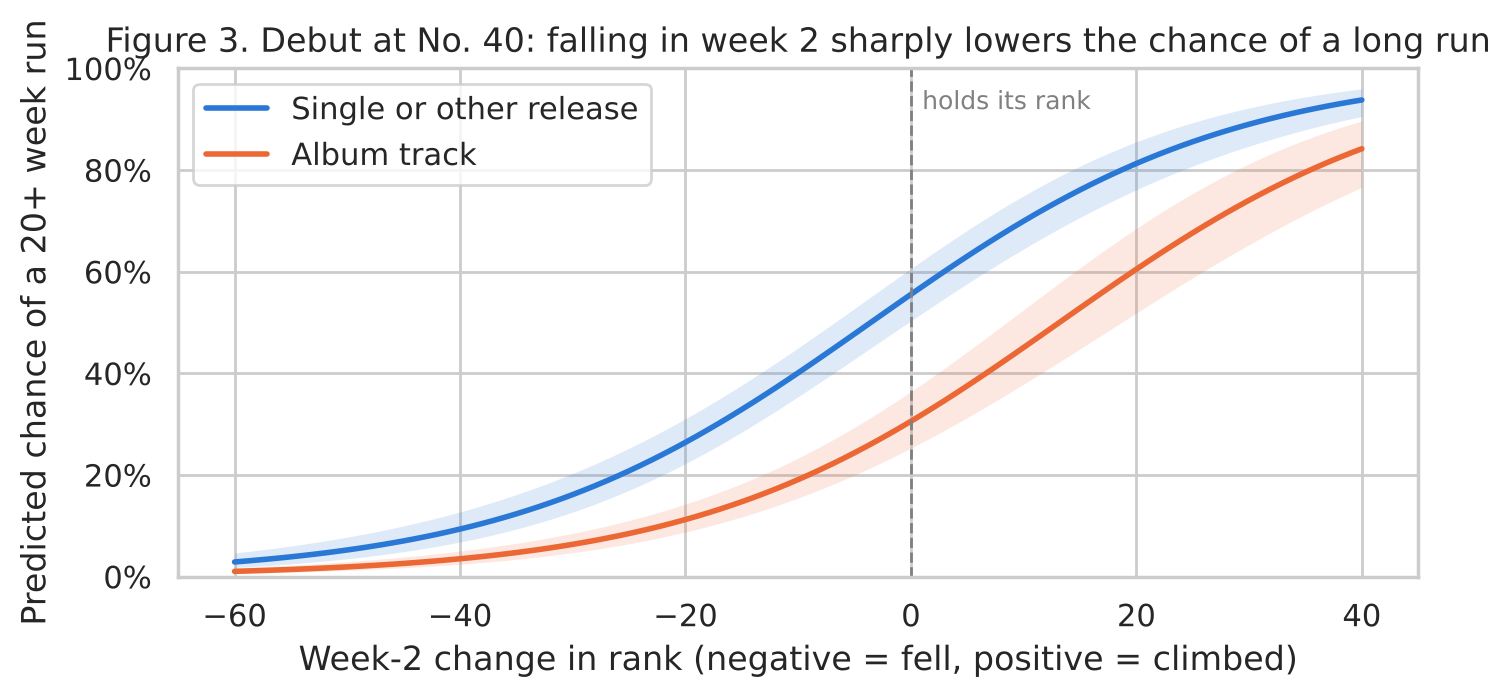

In [7]:
grid = pd.DataFrame({"week2_change": np.arange(-60, 41)})
fig, ax = plt.subplots(figsize=(8, 3.3))
for album, color, label in [(0, BLUE, "Single or other release"), (1, ORANGE, "Album track")]:
    g = grid.assign(debut_rank=40, album_track=album)
    pred = logit1.get_prediction(g).summary_frame()
    ax.plot(g["week2_change"], pred["predicted"], color=color, linewidth=2, label=label)
    ax.fill_between(g["week2_change"], pred["ci_lower"], pred["ci_upper"], color=color, alpha=0.15, linewidth=0)
ax.axvline(0, color="gray", linewidth=1, linestyle="--")
ax.text(1, 0.92, "holds its rank", color="gray", fontsize=9)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylim(0, 1)
ax.set_xlabel("Week-2 change in rank (negative = fell, positive = climbed)")
ax.set_ylabel("Predicted chance of a 20+ week run")
ax.set_title("Figure 3. Debut at No. 40: falling in week 2 sharply lowers the chance of a long run")
ax.legend(loc="upper left")
plt.show()

Album tracks sit below other songs at every level of week-2 movement. The shaded bands are 95% confidence intervals.

**Second check: number of weeks.** A linear regression on log(weeks) with the same inputs.

In [8]:
ols1 = smf.ols("log_weeks ~ week2_change + debut_rank + album_track", data=h1).fit(cov_type="HC1")
print(f"each 10 spots lost in week 2 -> {np.exp(-10 * ols1.params['week2_change']) - 1:+.1%} weeks | "
      f"album track -> {np.exp(ols1.params['album_track']) - 1:+.1%} weeks | "
      f"R-squared {ols1.rsquared:.2f} | residual skew {ols1.resid.skew():.2f}")

each 10 spots lost in week 2 -> -24.9% weeks | album track -> -43.7% weeks | R-squared 0.48 | residual skew 0.33


The linear model agrees: each 10 spots lost in week 2 goes with about **25% fewer weeks**, and album tracks chart 44% fewer weeks. The three signals explain 48% of the differences between songs (R² = 0.48), and the model's errors are balanced (skew 0.33), so the log scale works.

**Outliers.** The songs the model got most wrong:

In [9]:
h1["chance"] = p_hat
cols = ["title", "artist", "debut_rank", "week2_change", "album_track", "weeks_on_chart_total", "chance"]
misses = pd.concat([h1[(h1["long_run"] == 1) & (h1["chance"] < 0.05)].assign(miss="long run, chance under 5%"),
                    h1[(h1["long_run"] == 0) & (h1["chance"] > 0.9)].assign(miss="short run, chance over 90%")])
display(misses.set_index("miss")[cols].round(2))

,title,artist,debut_rank,week2_change,album_track,weeks_on_chart_total,chance
miss,,,,,,,
"long run, chance under 5%",All Mine,Brent Faiyaz,42,-47.0,1,20,0.02
"long run, chance under 5%",One Thing At A Time,Morgan Wallen,37,-44.0,1,30,0.03
"short run, chance over 90%",Fingers Crossed,Lauren Spencer-Smith,69,50.0,0,19,0.92
"short run, chance over 90%",Heyy,Lil Baby,77,56.0,0,12,0.92
"short run, chance over 90%",Painting Pictures,Superstar Pride,99,65.0,0,15,0.91
"short run, chance over 90%",Surface Pressure,Jessica Darrow,54,40.0,0,19,0.91
"short run, chance over 90%",Tobey,"Eminem, Big Sean & BabyTron",95,68.0,0,5,0.93


- **Morgan Wallen's "One Thing At A Time"** fell 44 spots in week 2 but lasted 30 weeks after it was pushed to country radio, where it hit No. 1 on MusicRow's radio chart (Cantrell, 2023). Our flag also counts it as an album track, because it debuted with two other songs from a 3-song EP.
- **Brent Faiyaz's "All Mine"** fell 47 spots, then slowly grew into a 20-week run.
- **Big week-2 jumps that still fell short**, like Eminem, Big Sean and BabyTron's "Tobey" (up 68 spots, gone after 5 weeks). Two others lasted 19 weeks, one short of our cutoff.

**Lesson.** Promotion after week 2, like radio, can override the early signal. Also, a song that debuts at No. 1 cannot climb, so week-2 movement depends on debut rank, which is why every model includes debut rank.

**Keeping more songs.** Our TA asked whether we need to drop recent debuts. Whether a song reached 20 weeks is already known once it has reached 20 weeks or left the chart, so we rerun the model on every such debut.

In [10]:
# Robustness: keep every debut whose 20-week outcome is already known, not only songs followed a year.
# The outcome is known once a song has reached 20 weeks or has left the chart.
known = df[df["new_entry"] & df["week2_change"].notna()
           & ((df["weeks_on_chart_total"] >= 20) | ~df["still_charting"])].copy()
known["long_run"] = known["long_run"].astype(int)
known["album_track"] = known["album_track"].astype(int)
logit1_all = smf.logit("long_run ~ week2_change + debut_rank + album_track", data=known).fit(disp=0)
b_all = logit1_all.params["week2_change"]
print(f"songs: {len(known)} (main sample: {len(h1)})")
print(f"odds ratio for a 10-spot drop in week 2: {np.exp(-10 * b_all):.2f}, two-sided p = {logit1_all.pvalues['week2_change']:.1g}")

songs: 1619 (main sample: 1364)
odds ratio for a 10-spot drop in week 2: 0.53, two-sided p = 1e-51


With 1,619 songs, a 10-spot drop multiplies the odds of a long run by 0.53, almost the same as 0.54. We keep the one-year sample as our main test because we preregistered it.

### Hypothesis 2: established artists
**Sample.** All 2,350 songs followed at least a year; 84% are by established artists. The outcome is log(weeks), so results read as percent changes.

In [11]:
h2 = followed.copy()
h2["established"] = h2["established"].astype(int)
h2["album_track"] = h2["album_track"].astype(int)
h2["top20"] = (h2["debut_rank"] <= 20).astype(int)
print("songs:", len(h2), "| share by established artists:", round(h2["established"].mean(), 3))
display(h2.groupby(["top20", "established"])["weeks_on_chart_total"].agg(songs="size", median_weeks="median"))

ols2 = smf.ols("log_weeks ~ established + debut_rank + album_track", data=h2).fit(cov_type="HC1")
display(show_fit(ols2, ["established", "debut_rank", "album_track"]))
eff, ci = ols2.params["established"], ols2.conf_int().loc["established"]
print(f"established artist -> {np.exp(eff) - 1:+.1%} weeks (95% CI {np.exp(ci[0]) - 1:+.1%} to {np.exp(ci[1]) - 1:+.1%})"
      f" | album track -> {np.exp(ols2.params['album_track']) - 1:+.1%} | R-squared {ols2.rsquared:.2f}")

songs: 2350 | share by established artists: 0.842


songs  median_weeks
top20 established                     
0     0              354           6.0
      1             1649           2.0
1     0               17          20.0
      1              330          12.0

,estimate,95% CI low,95% CI high,p-value
established,-0.419,-0.565,-0.272,< 0.001
debut_rank,-0.020,-0.021,-0.018,< 0.001
album_track,-1.207,-1.293,-1.122,< 0.001


established artist -> -34.2% weeks (95% CI -43.2% to -23.8%) | album track -> -70.1% | R-squared 0.31


**Raw numbers.** Before any model, newer artists' songs last longer outside the top 20 (median 6 weeks against 2) and inside it (20 against 12). Inside the top 20, most of that gap is album releases: 70% of established artists' top-20 debuts are album tracks.

**Summarizing.** At the same debut rank and album status, established artists' songs chart about **34% fewer weeks** (95% CI 24% to 43% fewer). Album tracks chart about 70% fewer weeks, the biggest single effect.

**Top-20 check.** We planned to test whether the effect is strongest for top-20 debuts. An interaction lets the effect differ inside and outside the top 20.

In [12]:
ols2b = smf.ols("log_weeks ~ established * top20 + debut_rank + album_track", data=h2).fit(cov_type="HC1")
inside_test = ols2b.t_test("established + established:top20 = 0")
print(f"established OUTSIDE the top 20: {np.exp(ols2b.params['established']) - 1:+.1%} weeks")
print(f"established INSIDE the top 20:  {np.exp(float(np.squeeze(inside_test.effect))) - 1:+.1%} weeks "
      f"(p = {float(np.squeeze(inside_test.pvalue)):.2f})")
print(f"difference between the two (interaction): two-sided p = {ols2b.pvalues['established:top20']:.3f}")

established OUTSIDE the top 20: -37.6% weeks
established INSIDE the top 20:  +48.1% weeks (p = 0.17)
difference between the two (interaction): two-sided p = 0.004


**It went the opposite way from our prediction.** Outside the top 20, established artists' songs chart about **38% fewer weeks**. Inside the top 20, they chart about 48% *more*, but only 17 top-20 debuts are by newer artists, so this is not significant (p = 0.17). The difference between the two groups is significant (p = 0.004). Figure 4 shows predicted weeks for a non-album song.

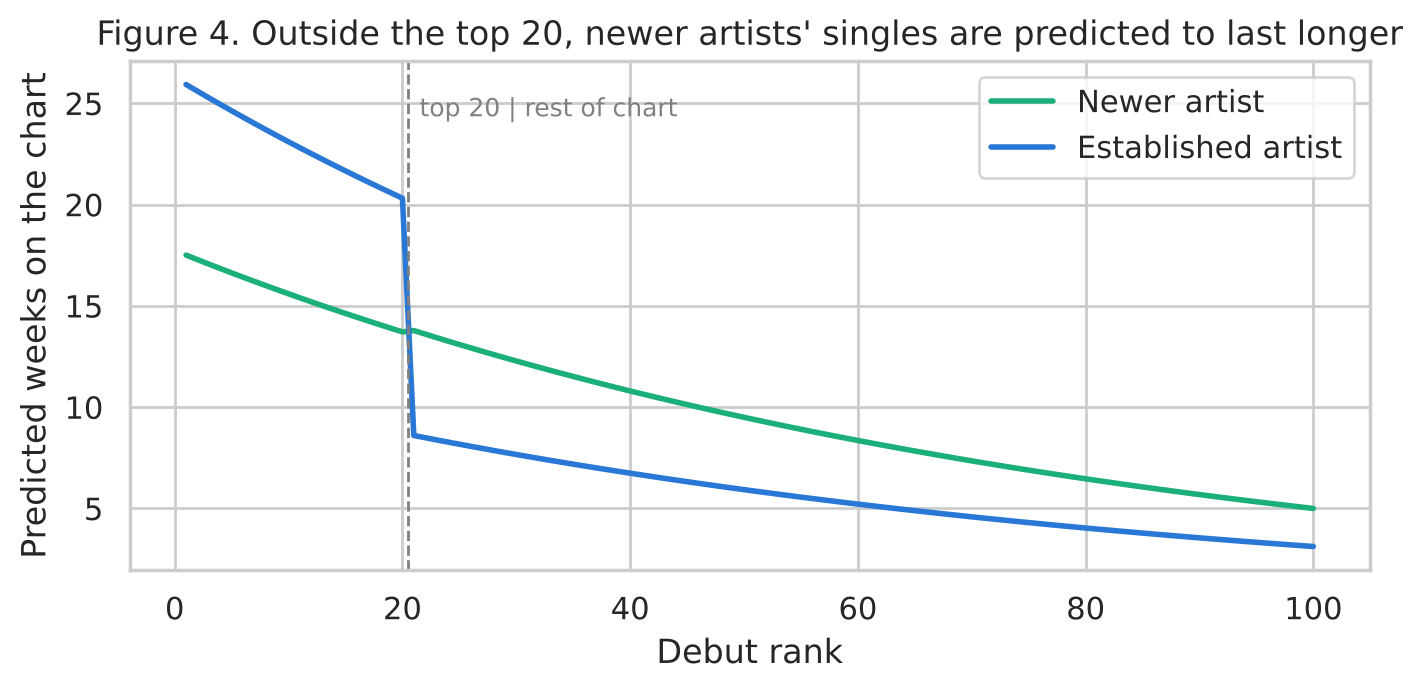

newer-artist top-20 debuts: 17 | lasted 20+ weeks: 9
examples: Creepin' (Metro Boomin, The Weeknd & 21 Savage, 47 wks); APT. (ROSE & Bruno Mars, 45 wks); Million Dollar Baby (Tommy Richman, 33 wks); Superhero (Heroes & Villains) (Metro Boomin, Future & Chris Brown, 24 wks); Boy's A Liar, Pt. 2 (PinkPantheress & Ice Spice, 22 wks); Tomorrow 2 (GloRilla & Cardi B, 22 wks)


In [13]:
grid = pd.DataFrame({"debut_rank": np.arange(1, 101)})
grid["top20"] = (grid["debut_rank"] <= 20).astype(int)
fig, ax = plt.subplots(figsize=(8, 3.3))
for est, color, label in [(0, GREEN, "Newer artist"), (1, BLUE, "Established artist")]:
    g = grid.assign(established=est, album_track=0)
    ax.plot(g["debut_rank"], np.exp(ols2b.predict(g)), color=color, linewidth=2, label=label)
ax.axvline(20.5, color="gray", linestyle="--", linewidth=1)
ax.text(21.5, ax.get_ylim()[1] * 0.9, "top 20 | rest of chart", color="gray", fontsize=9)
ax.set_xlabel("Debut rank")
ax.set_ylabel("Predicted weeks on the chart")
ax.set_title("Figure 4. Outside the top 20, newer artists' singles are predicted to last longer")
ax.legend()
plt.show()

new20 = h2[(h2["top20"] == 1) & (h2["established"] == 0)]
print(f"newer-artist top-20 debuts: {len(new20)} | lasted 20+ weeks: {(new20['weeks_on_chart_total'] >= 20).sum()}")
print("examples:", "; ".join(new20.sort_values("weeks_on_chart_total", ascending=False)
                              .apply(lambda r: f"{r['title']} ({r['artist']}, {r['weeks_on_chart_total']} wks)", axis=1).head(6)))

**Predicting.** For a non-album song that debuts at No. 50, the model predicts about 9.5 weeks for a newer artist and 6 for an established one.

**Outliers.** The 17 newer-artist top-20 debuts are a mixed group. Nine lasted 20+ weeks, including real breakouts like Tommy Richman's "Million Dollar Baby" (33 weeks). Others are famous artists our flag calls new by a technicality: The Beatles' "Now And Then," Kendrick Lamar's "The Heart Part 5," and Kanye West's "Carnival," credited to his group ¥$. With so few songs, the top-20 result is a hint, not a finding.

**Robustness.** The main effect holds for non-album songs only (about −35%) and for debuts from 2023 on (−33%), which have a full 3-year look-back.

In [14]:
nonalbum = smf.ols("log_weeks ~ established + debut_rank", data=h2[h2["album_track"] == 0]).fit(cov_type="HC1")
late = smf.ols("log_weeks ~ established + debut_rank + album_track",
               data=h2[h2["first_week"] >= "2023-01-01"]).fit(cov_type="HC1")
print(f"non-album songs only (n={int(nonalbum.nobs)}): established -> {np.exp(nonalbum.params['established']) - 1:+.1%}, "
      f"p = {nonalbum.pvalues['established']:.2g}")
print(f"debuts from 2023 on (n={int(late.nobs)}): established -> {np.exp(late.params['established']) - 1:+.1%}, "
      f"p = {late.pvalues['established']:.2g}")

non-album songs only (n=1157): established -> -34.7%, p = 8e-07
debuts from 2023 on (n=1721): established -> -32.8%, p = 5.8e-06


**Stricter definitions.** Our TA felt our flag is too loose, since one week on the chart in 3 years makes an artist established. We test two stricter versions (3 or more different Hot 100 songs, or a top-10 hit, in the past 3 years), plus a Cox model on all 2,924 debuts, which keeps recent songs.

In [15]:
# Robustness: stricter definitions of "established"
rows = []
for flag, label in [("established", "Preregistered: any Hot 100 entry"),
                    ("established_3songs", "3 or more different Hot 100 songs"),
                    ("established_top10", "At least one top-10 hit")]:
    fit = smf.ols(f"log_weeks ~ {flag} + debut_rank + album_track", data=h2).fit(cov_type="HC1")
    rows.append({"established means (lead artist, past 3 years)": label,
                 "share of songs": round(h2[flag].mean(), 2),
                 "newer-artist top-20 debuts": int(((h2[flag] == 0) & (h2["top20"] == 1)).sum()),
                 "change in weeks": f"{np.exp(fit.params[flag]) - 1:+.0%}",
                 "two-sided p": round(fit.pvalues[flag], 4)})
display(pd.DataFrame(rows))

# Robustness: keep all debuts, using a Cox model that treats still-charting songs as unfinished
debuts = df[df["new_entry"]].copy()
cox_h2 = PHReg(debuts["weeks_on_chart_total"], debuts[["established", "debut_rank", "album_track"]].astype(float),
               status=debuts["complete_run"].astype(int)).fit()
print(f"all {len(debuts)} debuts: weekly hazard of leaving for established artists = "
      f"{np.exp(cox_h2.params[0]):.2f}x, two-sided p = {cox_h2.pvalues[0]:.1g}")

,"established means (lead artist, past 3 years)",share of songs,newer-artist top-20 debuts,change in weeks,two-sided p
0,Preregistered: any Hot 100 entry,0.84,17,-34%,0.0000
1,3 or more different Hot 100 songs,0.67,52,-20%,0.0001
2,At least one top-10 hit,0.49,76,-15%,0.0006


all 2924 debuts: weekly hazard of leaving for established artists = 1.36x, two-sided p = 2e-08


The direction holds, but the gap shrinks to 20% and 15% fewer weeks with the stricter flags, and all three are significant. A stricter flag moves artists with only small past hits into the "newer" group, which narrows the gap. The Cox model agrees: established artists' songs are 1.36 times as likely to leave the chart in any given week (p < 0.001).

### Hypothesis 3: front-loaded streaming
**Sample.** Songs followed at least a year that matched a Spotify song, with three filters:
- **Timing check.** The Billboard debut is exactly 9 days after the first Spotify week, so both charts measure the same week. This also screens out wrong matches.
- **Both weeks in the Top 200.** As our TA advised, so both weeks are real stream counts. The preregistered 0-stream version is a check.
- **Finished runs.** As in Hypotheses 1 and 2, songs that debuted by October 2025.

In [16]:
h3 = df[df["new_entry"] & df["spotify_first_in_window"].eq(True) & df["front_load"].notna()].copy()
print("matched debuts with an observable Spotify week 2:", len(h3))
h3 = h3[h3["spotify_lag_days"] == 9].copy()  # the gap is computed in the cleaning notebook
h3["log_streams_2wk"] = np.log(h3["streams_2wk"])
h3["album_track"] = h3["album_track"].astype(int)
h3["finished"] = h3["complete_run"].astype(int)
print("after the 9-day check:", len(h3))

# Every debut through 2026 that passes the checks, including songs still on the chart (used by the Cox check)
h3_all = h3[h3["fell_out_week2"].eq(False)].copy()

# Songs followed at least a year, as in Hypotheses 1 and 2
h3 = h3[h3["followed_1yr"]].copy()
print("followed at least a year:", len(h3))

# Preregistered version, kept as a robustness check: a week outside the Top 200 counts as 0 streams
h3_prereg = h3.copy()
h3_prereg["log_streams_2wk_upper"] = np.log(h3_prereg["streams_first_week"] + h3_prereg["streams_week2_upper"])

# Main sample: only songs in the Top 200 both weeks, so both weeks are real stream counts
h3 = h3[h3["fell_out_week2"].eq(False)].copy()
print("in the Top 200 both weeks:", len(h3), "| still charting:", int((1 - h3["finished"]).sum()),
      "| share with a long run:", round(h3["long_run"].mean(), 3))
print("debut years:", h3["first_week"].dt.year.value_counts().sort_index().to_dict(),
      f"| F ranges from {h3['front_load'].min():.2f} to {h3['front_load'].max():.2f}, median {h3['front_load'].median():.2f}")

# Run length for songs grouped by F
bands = pd.cut(h3["front_load"], [0, 0.5, 0.6, 0.7, 1], labels=["0.5 or less", "0.5 to 0.6", "0.6 to 0.7", "over 0.7"])
display(h3.groupby(bands, observed=True)
          .agg(songs=("front_load", "size"), median_weeks=("weeks_on_chart_total", "median"),
               share_long_run=("long_run", "mean"), share_album_tracks=("album_track", "mean"))
          .round(2).rename_axis("F (share of early streams in week 1)"))

matched debuts with an observable Spotify week 2: 2182
after the 9-day check: 1888
followed at least a year: 1566
in the Top 200 both weeks: 1067 | still charting: 1 | share with a long run: 0.23
debut years: {2022: 290, 2023: 285, 2024: 270, 2025: 222} | F ranges from 0.22 to 0.83, median 0.61


,songs,median_weeks,share_long_run,share_album_tracks
F (share of early streams in week 1),,,,
0.5 or less,198,20.0,0.53,0.23
0.5 to 0.6,294,11.0,0.33,0.37
0.6 to 0.7,446,3.0,0.09,0.82
over 0.7,129,2.0,0.02,0.98


**The raw pattern.** 1,067 songs pass, and only one is still charting. Run length falls steadily as F rises: songs with F of 0.5 or less (steady or growing streams) have a median run of 20 weeks, while songs above 0.7 have a median of 2. Album tracks make up 23% of the steadiest group and 98% of the most front-loaded one, which we come back to below.

In [17]:
ols3 = smf.ols("log_weeks ~ front_load + log_streams_2wk", data=h3).fit(cov_type="HC1")
display(show_fit(ols3, ["front_load", "log_streams_2wk"]))
b, ci = ols3.params["front_load"], ols3.conf_int().loc["front_load"]
print(f"F up by 0.1 -> {np.exp(0.1 * b) - 1:+.1%} weeks (95% CI {np.exp(0.1 * ci[0]) - 1:+.1%} to "
      f"{np.exp(0.1 * ci[1]) - 1:+.1%}) | R-squared {ols3.rsquared:.2f} | residual skew {ols3.resid.skew():.2f}")

# Preregistered versions, kept as checks
ols3p = smf.ols("log_weeks ~ front_load + log_streams_2wk", data=h3_prereg).fit(cov_type="HC1")
ols3u = smf.ols("log_weeks ~ front_load_upper + log_streams_2wk_upper", data=h3_prereg).fit(cov_type="HC1")
print(f"as preregistered, n = {len(h3_prereg)}: missing week 2 = 0 streams -> beta_F = {ols3p.params['front_load']:.2f}"
      f" (p = {ols3p.pvalues['front_load']:.1g}); = No. 200 streams -> beta_F = {ols3u.params['front_load_upper']:.2f}"
      f" (p = {ols3u.pvalues['front_load_upper']:.1g})")

# The weeks we planned: debuts from Oct 12, 2024 (Spotify week of Oct 3, 2024) to Oct 18, 2025
window = h3[h3["first_week"] >= "2024-10-12"]
ols3w = smf.ols("log_weeks ~ front_load + log_streams_2wk", data=window).fit(cov_type="HC1")
print(f"planned weeks only (Oct 2024 to Oct 2025 debuts), n = {len(window)}: "
      f"F up by 0.1 -> {np.exp(0.1 * ols3w.params['front_load']) - 1:+.1%} weeks (p = {ols3w.pvalues['front_load']:.1g})")

,estimate,95% CI low,95% CI high,p-value
front_load,-6.747,-7.311,-6.184,< 0.001
log_streams_2wk,0.974,0.877,1.071,< 0.001


F up by 0.1 -> -49.1% weeks (95% CI -51.9% to -46.1%) | R-squared 0.46 | residual skew 0.38


as preregistered, n = 1566: missing week 2 = 0 streams -> beta_F = -3.02 (p = 3e-88); = No. 200 streams -> beta_F = -6.64 (p = 2e-139)
planned weeks only (Oct 2024 to Oct 2025 debuts), n = 269: F up by 0.1 -> -43.2% weeks (p = 2e-23)


**Summarizing.** At the same total early streams, raising F by 0.1 (for example, from a 60/40 split to 70/30) goes with about **49% fewer weeks** (95% CI 46% to 52% fewer). Songs with more total streams last longer. The model explains 46% of the differences between songs (R² = 0.46).

The preregistered versions agree. Counting a missing week 2 as 0 streams (1,566 songs) or as the No. 200 song's streams both give significant negative effects, and using only the October 2024 to October 2025 debuts we planned (269 songs) gives 43% fewer weeks.

In [18]:
# Predicting: weeks on the chart for songs with the median early streams and different F
typical = h3["log_streams_2wk"].median()
pred = pd.DataFrame({"front_load": [0.5, 0.6, 0.7], "log_streams_2wk": typical})
pred["predicted weeks"] = np.exp(ols3.predict(pred)).round(1)
display(pred.assign(**{"2-week streams (millions)": round(np.exp(typical) / 1e6, 1)}).drop(columns="log_streams_2wk"))

,front_load,predicted weeks,2-week streams (millions)
0,0.5,9.5,9.7
1,0.6,4.9,9.7
2,0.7,2.5,9.7


**Predicting.** For a song with the typical 9.7 million streams over its first two weeks, the model predicts about 9.5 weeks on the chart for an even 50/50 split, 4.9 weeks for 60/40, and 2.5 weeks for 70/30.

**Could something else explain this?** Two things might:
- **Album releases.** Album tracks are more front-loaded (median F 0.65, against 0.54) and also fade faster.
- **The week-2 drop.** Spotify streams count toward the Hot 100, so fading streams also mean a Billboard drop, our Hypothesis 1 signal.

We test both. We also fit a Cox model on all 1,254 debuts through 2026, to include songs still on the chart.

In [19]:
# Does F still matter after accounting for album releases and the week-2 drop?
ols3a = smf.ols("log_weeks ~ front_load + log_streams_2wk + album_track", data=h3).fit(cov_type="HC1")
ols3n = smf.ols("log_weeks ~ front_load + log_streams_2wk", data=h3[h3["album_track"] == 0]).fit(cov_type="HC1")
h3w2 = h3.dropna(subset=["week2_change"])  # songs still on the Hot 100 in week 2
ols3h = smf.ols("log_weeks ~ front_load + log_streams_2wk + week2_change + debut_rank + album_track",
                data=h3w2).fit(cov_type="HC1")
checks = pd.DataFrame([
    ("Preregistered inputs (main test)", ols3),
    ("+ album release", ols3a),
    ("Non-album songs only", ols3n),
    ("+ week-2 change, debut rank, and album release", ols3h),
], columns=["model", "fit"])
checks["songs"] = [int(f.nobs) for f in checks["fit"]]
checks["F up by 0.1 -> weeks"] = [f"{np.exp(0.1 * f.params['front_load']) - 1:+.0%}" for f in checks["fit"]]
checks["two-sided p"] = [f"{f.pvalues['front_load']:.1g}" for f in checks["fit"]]
display(checks.drop(columns="fit"))
print("median F, album tracks vs other releases:", h3.groupby("album_track")["front_load"].median().round(2).to_dict())
print(f"correlation between F and week-2 change: r = {h3w2['front_load'].corr(h3w2['week2_change']):.2f}")

# Cox check on all debuts through 2026, counting still-charting songs only for the weeks we have seen
cox3 = PHReg(h3_all["weeks_on_chart_total"], h3_all[["front_load", "log_streams_2wk"]].astype(float),
             status=h3_all["finished"]).fit()
b, se = cox3.params[0], cox3.bse[0]
print(f"Cox model, all {len(h3_all)} debuts ({int((1 - h3_all['finished']).sum())} still charting): "
      f"HR for F +0.1 = {np.exp(0.1 * b):.2f} (95% CI {np.exp(0.1 * (b - 1.96 * se)):.2f} to "
      f"{np.exp(0.1 * (b + 1.96 * se)):.2f}), p = {cox3.pvalues[0]:.1g}")

,model,songs,F up by 0.1 -> weeks,two-sided p
0,Preregistered inputs (main test),1067,-49%,1e-121
1,+ album release,1067,-43%,1e-66
2,Non-album songs only,419,-35%,2e-12
3,"+ week-2 change, debut rank, and album release",902,-21%,6e-08


median F, album tracks vs other releases: {0: 0.54, 1: 0.65}
correlation between F and week-2 change: r = -0.80


Cox model, all 1254 debuts (47 still charting): HR for F +0.1 = 2.12 (95% CI 1.96 to 2.29), p = 2e-78


**F still matters.**
- With an album control, 0.1 more F goes with 43% fewer weeks, and among non-album songs alone, 35% fewer.
- F and the week-2 drop are closely linked (r = −0.80). Even comparing songs with the same debut rank, week-2 movement, and album status, 0.1 more F goes with 21% fewer weeks. So Spotify adds something the Billboard chart does not show, though most of F's signal overlaps with the week-2 drop.
- The Cox model on all debuts agrees: each 0.1 of F makes a song about 2.1 times as likely to leave the chart in a given week (95% CI 1.96 to 2.29).

All of these are significant (p < 0.001). **Figure 5** compares steady songs (F ≤ 0.6) with fading songs (F > 0.6), separately for album tracks and other releases.

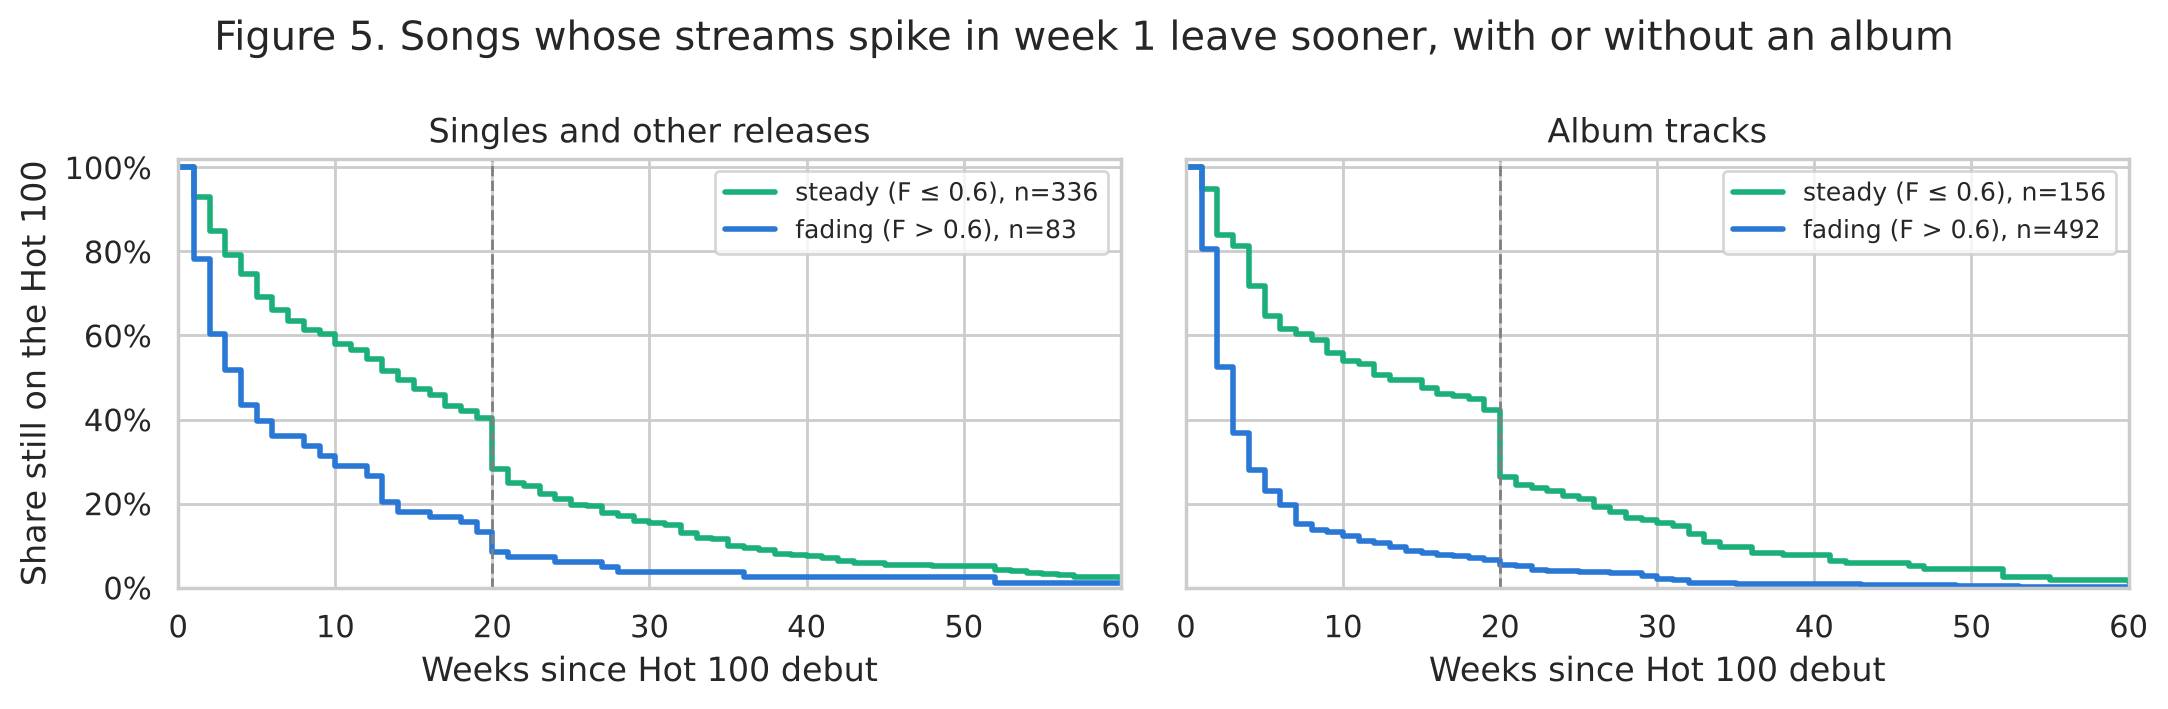

songs  median_weeks  share_long_run
release       streams                                              
album track   steady (F ≤ 0.6)    156          13.0            0.42
              fading (F > 0.6)    492           3.0            0.07
other release steady (F ≤ 0.6)    336          14.0            0.40
              fading (F > 0.6)     83           4.0            0.13

In [20]:
groups = pd.cut(h3["front_load"], [0, 0.6, 1], labels=["steady (F ≤ 0.6)", "fading (F > 0.6)"])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (album, title) in zip(axes, [(0, "Singles and other releases"), (1, "Album tracks")]):
    songs_in_panel = h3[h3["album_track"] == album]
    for (label, part), color in zip(songs_in_panel.groupby(groups.loc[songs_in_panel.index], observed=True), [GREEN, BLUE]):
        km = SurvfuncRight(part["weeks_on_chart_total"], part["finished"])
        ax.step(np.r_[0, km.surv_times], np.r_[1, km.surv_prob], where="post", color=color, linewidth=2,
                label=f"{label}, n={len(part)}")
    ax.axvline(20, color="gray", linestyle="--", linewidth=1)
    ax.set_xlim(0, 60)
    ax.set_title(title)
    ax.set_xlabel("Weeks since Hot 100 debut")
    ax.legend(loc="upper right", fontsize=9)
axes[0].set_ylabel("Share still on the Hot 100")
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[0].set_ylim(0, 1.02)
fig.suptitle("Figure 5. Songs whose streams spike in week 1 leave sooner, with or without an album")
plt.tight_layout()
plt.show()

display(h3.groupby([h3["album_track"].map({0: "other release", 1: "album track"}), groups], observed=True)
          .agg(songs=("front_load", "size"), median_weeks=("weeks_on_chart_total", "median"),
               share_long_run=("long_run", "mean"))
          .round(2).rename_axis(["release", "streams"]))

**Reading Figure 5.** In both panels, fading songs drop off much faster. Among other releases, 40% of steady songs reach 20 weeks (the dashed line), against 13% of fading songs. Among album tracks, it is 42% against 7%. A steady album track lasts about as long as a steady single, so whether a song's streams hold up in week 2 matters at least as much as whether it came with an album.

**Outliers.** The songs the model got most wrong:

In [21]:
h3["predicted_weeks"] = np.exp(ols3.fittedvalues)
cols = ["title", "artist", "album_track", "front_load", "weeks_on_chart_total", "predicted_weeks"]
order = ols3.resid.sort_values()
misses = pd.concat([h3.loc[order.index[::-1][:5]].assign(miss="lasted far longer"),
                    h3.loc[order.index[:5]].assign(miss="left far sooner")])
display(misses.set_index("miss")[cols].round(2))

,title,artist,album_track,front_load,weeks_on_chart_total,predicted_weeks
miss,,,,,,
lasted far longer,Rock And A Hard Place,Bailey Zimmerman,0,0.59,54,2.86
lasted far longer,Thank God,Kane Brown With Katelyn Brown,0,0.60,42,2.36
lasted far longer,Something In The Orange,Zach Bryan,0,0.53,66,3.94
lasted far longer,Snooze,SZA,1,0.64,70,5.12
lasted far longer,Thought You Should Know,Morgan Wallen,0,0.62,52,4.32
left far sooner,You're Losing Me,Taylor Swift,0,0.38,1,30.17
left far sooner,Noid,"Tyler, The Creator",0,0.27,5,94.93
left far sooner,Poland,Lil Yachty,0,0.30,3,30.46
left far sooner,Smeraldo Garden Marching Band,Jimin & Loco,0,0.51,1,8.96


- **Radio.** Most songs that lasted far longer than predicted are country songs, like Zach Bryan's "Something In The Orange" (66 weeks, predicted 4) and Bailey Zimmerman's "Rock And A Hard Place" (54 weeks, predicted 3). Their streams faded at a normal pace, so radio play, which Spotify data cannot see, likely kept them on the chart.
- **Partial first weeks.** Spotify's chart week runs Friday to Thursday, so a song released midweek gets only a few days in week 1 and looks like a grower. Kendrick Lamar's "Euphoria," released on a Tuesday, lasted 17 weeks, but the model predicted 142, more than any song in our data. The model is least reliable for songs with very low F.

## Evaluation of significance
Each row of the table is one test, using its preregistered controls. *One-sided p* is the chance of a result this strong if there were no relationship, counting only the direction we predicted. "Reject at 0.017" uses our stricter cutoff for three tests. The *clustered* column reruns each test treating songs by the same artist as one group, since they rise and fall together. The *estimate* is each model's raw coefficient, so compare the yes/no columns, not the estimates.

In [22]:
def one_sided(fit, term, predicted_sign, p2=None):
    b = fit.params[term]
    p2 = fit.pvalues[term] if p2 is None else p2
    return p2 / 2 if np.sign(b) == predicted_sign else 1 - p2 / 2

def clustered(fit, data, kind="ols"):
    # Same model, but songs by the same lead artist are treated as one group when computing margins of error
    groups = data["lead_artist"].astype("category").cat.codes
    if kind == "logit":
        return smf.logit(fit.model.formula, data=data).fit(disp=0, cov_type="cluster", cov_kwds={"groups": groups})
    return smf.ols(fit.model.formula, data=data).fit(cov_type="cluster", cov_kwds={"groups": groups})

cox3_c = PHReg(h3_all["weeks_on_chart_total"], h3_all[["front_load", "log_streams_2wk"]].astype(float),
               status=h3_all["finished"]).fit(groups=h3_all["lead_artist"].astype("category").cat.codes.values)

tests = [  # label, model, alternative, fit, clustered fit, term, predicted sign, songs
    ("H1", "Logit, long run ~ week-2 change", "β > 0", logit1, clustered(logit1, h1, "logit"), "week2_change", +1, len(h1)),
    ("H1 (secondary)", "OLS, log weeks ~ week-2 change", "β > 0", ols1, clustered(ols1, h1), "week2_change", +1, len(h1)),
    ("H2", "OLS, log weeks ~ established", "β < 0", ols2, clustered(ols2, h2), "established", -1, len(h2)),
    ("H2 (interaction)", "OLS, established × top-20", "β < 0", ols2b, clustered(ols2b, h2), "established:top20", -1, len(h2)),
    ("H3", "OLS, log weeks ~ F (Top 200 both weeks)", "β < 0", ols3, clustered(ols3, h3), "front_load", -1, len(h3)),
    ("H3 (as preregistered)", "OLS, log weeks ~ F (0 streams if out)", "β < 0", ols3p, clustered(ols3p, h3_prereg), "front_load", -1, len(h3_prereg)),
]
rows = [(t, m, alt, fit.params[term], one_sided(fit, term, sign), one_sided(cfit, term, sign), n)
        for t, m, alt, fit, cfit, term, sign, n in tests]
rows.append(("H3 (Cox, all debuts)", "Cox, exit hazard ~ F", "log HR > 0", cox3.params[0],
             one_sided(cox3, 0, +1, cox3.pvalues[0]), one_sided(cox3_c, 0, +1, cox3_c.pvalues[0]), len(h3_all)))
sig = pd.DataFrame(rows, columns=["test", "model", "alternative", "estimate", "one-sided p", "one-sided p, clustered", "n"])
sig["reject at 0.05"] = np.where(sig["one-sided p"] < 0.05, "yes", "no")
sig["reject at 0.017"] = np.where(sig["one-sided p"] < 0.05 / 3, "yes", "no")
sig["still rejects at 0.017 when clustered"] = np.where(sig["one-sided p, clustered"] < 0.05 / 3, "yes", "no")
sig["estimate"] = sig["estimate"].round(4)
for col in ["one-sided p", "one-sided p, clustered"]:
    sig[col] = sig[col].map(lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}")
sig

,test,model,alternative,estimate,one-sided p,"one-sided p, clustered",n,reject at 0.05,reject at 0.017,still rejects at 0.017 when clustered
0,H1,"Logit, long run ~ week-2 change",β > 0,0.0623,< 0.001,< 0.001,1364,yes,yes,yes
1,H1 (secondary),"OLS, log weeks ~ week-2 change",β > 0,0.0286,< 0.001,< 0.001,1364,yes,yes,yes
2,H2,"OLS, log weeks ~ established",β < 0,-0.4186,< 0.001,< 0.001,2350,yes,yes,yes
3,H2 (interaction),"OLS, established × top-20",β < 0,0.8644,0.998,0.993,2350,no,no,no
4,H3,"OLS, log weeks ~ F (Top 200 both weeks)",β < 0,-6.7475,< 0.001,< 0.001,1067,yes,yes,yes
5,H3 (as preregistered),"OLS, log weeks ~ F (0 streams if out)",β < 0,-3.0187,< 0.001,< 0.001,1566,yes,yes,yes
6,"H3 (Cox, all debuts)","Cox, exit hazard ~ F",log HR > 0,7.5045,< 0.001,< 0.001,1254,yes,yes,yes


**Hypothesis 1: reject the null.** Week-2 movement predicts long runs (p < 0.001), and the linear model agrees. A 10-spot drop multiplies the odds of a 20-week run by about 0.54 (95% CI 0.49 to 0.58).

**Hypothesis 2: reject the null for the main effect** (p < 0.001), and it holds with stricter definitions. We **fail to reject** the null for the top-20 interaction, because it went the opposite way from our prediction. Read two-sided it is significant (p = 0.004, or 0.013 clustered), so we report it as a surprise to confirm with new data.

**Hypothesis 3: reject the null.** Front-loaded songs chart fewer weeks (p < 0.001) in the main test, in the preregistered 0-stream version, and in the Cox model. 0.1 more F goes with about 49% fewer weeks (95% CI 46% to 52%).

**Clustered errors** widen every margin of error but change no conclusion.

**What the p-values do not tell us.**
- With over 1,000 songs per test, even small effects can be significant, so we also report how big each effect is.
- Clustering by artist does not catch every way songs move together (for example, the same season), so our margins may still be a little too small.
- These are associations, not causes. A week-2 drop is a symptom of weak demand, not its cause.

## Conclusions
Within two weeks of a debut, four signals tell us a lot about whether a song will last:
1. **Week-2 movement (the strongest).** A non-album song that debuts at No. 40 has a 56% chance of a long run if it holds its rank, and 26% if it falls 20 spots. Adding week 2 makes our model explain almost four times as much.
2. **Album release.** Album tracks have about 65% lower odds of a long run than other songs with the same debut and week-2 movement. A big album debut usually means fans played the whole album once.
3. **Established artist (moderate, with a twist).** Established artists' songs chart about 34% fewer weeks (15% to 20% with stricter definitions), but only among songs that debut outside the top 20.
4. **Front-loaded streams.** Songs whose Spotify streams spike in week 1 leave sooner: a 70/30 split lasts about half as long as a 60/40 split with the same total streams. This adds to what the week-2 Billboard drop shows.

**Takeaway.** Debut rank alone is a poor guide, since short and long runs debut at similar ranks. After release week, look at week-2 movement, whether the song came with an album, and whether its streams held up.

## Limitations
**Gaps in our data**
- **Secondhand Billboard data.** A copying error would flow straight into our outcome. We found and fixed three, and all our consistency checks pass, so we think the remaining risk is small. Using only charts from 2022 on gives us under five years of data.
- **Unfinished recent runs.** Songs from 2026 are still charting and would look like quick flops, so our tests use debuts through October 2025. Checks that keep recent songs (Cox models, and a logistic model on known outcomes) give the same answers, but our findings describe 2022 to 2025.
- **Billboard's removal rule.** It cuts many runs at exactly 20 weeks, so past 20 weeks, run length partly reflects the rule and not listeners. This affects our log(weeks) models more than our 20-week cutoff. We kept weeks on the chart as our outcome over a combined chart-points score, since points mix how high a song charts with how long it stays.
- **Spotify limits.** We see streams from a song's first week on the Top 200, which may come after its release, and midweek releases get a short first week. Songs below No. 200 (1.4 to 2.7 million weekly streams) have no data, so our main test says nothing about the 32% of songs that fell out in week 2. Spotify is also only part of the Hot 100: radio, YouTube, Apple Music, and sales are missing, which is why radio-driven country songs outlasted our predictions.
- **Imperfect matching.** 75.5% of Billboard debuts matched a Spotify song, and most of the rest are small songs. We keep only matches that pass the 9-day timing check. Because the match uses only the first artist, two same-titled songs by one artist could be mixed up.

**Limits of our analysis**
- **Rough flags.** `album_track` misses albums that chart only one or two songs and counts short EPs. `established` uses only the lead artist, so artists known for features or side projects (like ¥$) count as new.
- **Album releases and front-loading overlap.** 86% of fading songs are album tracks. F still matters among non-album songs, but we cannot fully separate the two.
- **Significance.** Our stricter cutoff covers the three main tests, not every follow-up check, and all results are associations, not causes.

**Possible harms.** Our results describe US charts dominated by pop, hip-hop, and country, so they may not hold for genres whose fans listen elsewhere. If labels used a model like ours to drop songs after week 2, slow builders like "All Mine" or "One Thing At A Time" would lose the support that made them last, and the model would look more accurate than it is. Artists known mostly for features would also be treated as newcomers.

## What we changed after Phase 2 feedback
- **Spotify data for the same years as Billboard (TA comments 3 and 10).** We went from 20 Spotify weeks in 2026 to all 252 weeks from 2022 to 2026, so Hypothesis 3 now tests finished runs from the same years as Hypotheses 1 and 2.
- **Years used (comment 2).** Stated in the introduction.
- **Data cleaning.** Moved to its own notebook with every step explained. We show a few rows of the final data (comment 6) and define "early signals" (comment 7) and "matched songs" in Key terms.
- **Data description.** We explain why Billboard's removal rule exists and how it affects our outcome (comment 9), shortened the answer on whether people knew their data was collected (comment 12), and put the data description before cleaning (comment 11).
- **Limitations (comment 18).** Each limitation now says how it affects our results.
- **EDA.** Figure 2 is now a box plot that includes one-week songs (comments 25 and 29). Recent debuts are kept in robustness checks (comment 24), and terms like "Spearman 0.49" are explained in plain words (comment 28).
- **Preregistration (comments 1 and 20 to 22).** Hypotheses are phrased as "X is associated with Y, holding Z constant." We added stricter definitions of an established artist, and Hypothesis 3's main test keeps only songs in the Top 200 both weeks.
- **Chart-points score (comment 19).** Limitations explains why we kept weeks on the chart.
- **Readability.** Plain-language Key terms and the box "How to read our statistics."
- **Our own fixes.** We fixed three cleaning bugs (split song credits, the week-2 rank, and a broken count in the last three charts) and added clustered standard errors.

## Questions for reviewers
1. **Hypothesis 2 interaction.** It came out opposite to our prediction. Is it right to report it as an unexpected two-sided finding, or should we drop it until we can confirm it?
2. **Which "established" definition?** Stricter definitions shrink the effect from 34% to 15% to 20% fewer weeks. Should Phase 4 keep the preregistered flag as the main test or switch to a stricter one?
3. **Hypothesis 3 and week 2.** F and the week-2 drop are closely linked (r = −0.80), and F's effect shrinks from 49% to 21% once we add the week-2 drop. Should we present F as its own signal, or as an explanation of why songs drop in week 2?
4. **Week-2 sample.** Hypothesis 1 leaves out 134 songs that left in week 2 and came back (39 of them lasted 20+ weeks). Would a two-step model (survives week 1? then lasts 20 weeks?) be clearer?
5. **Clustered errors.** We group songs by lead artist. Would grouping by album release be better?

## Acknowledgements and bibliography
We thank Christian McDonald for keeping the Billboard archive public and updated each week, which made this project possible without scraping. The chart data belongs to Billboard (with data from Luminate) and Spotify.


**Data**
- Billboard. (2022–2026). *Billboard Hot 100* [weekly chart]. https://www.billboard.com/charts/hot-100/
- McDonald, C. (2026). *rwd-billboard-data* [GitHub repository, accessed Oct 14, 2026]. https://github.com/utdata/rwd-billboard-data
- Spotify. (2022–2026). *Weekly Top Songs, United States* [chart data, Jan 6, 2022 to Oct 29, 2026]. https://charts.spotify.com

**Literature**
- Askin, N., & Mauskapf, M. (2017). What makes popular culture popular? Product features and optimal differentiation in music. *American Sociological Review, 82*(5), 910–944.
- Bradlow, E. T., & Fader, P. S. (2001). A Bayesian lifetime model for the "Hot 100" Billboard songs. *Journal of the American Statistical Association, 96*(454), 368–381.
- Cantrell, L. B. (2023, May 5). Morgan Wallen nabs another MusicRow No. 1 with "One Thing At A Time." *MusicRow*. https://musicrow.com/2023/05/morgan-wallen-nabs-another-musicrow-no-1-with-one-thing-at-a-time/
- Cox, D. R. (1972). Regression models and life-tables. *Journal of the Royal Statistical Society: Series B, 34*(2), 187–220.
- Gebru, T., Morgenstern, J., Vecchione, B., Vaughan, J. W., Wallach, H., Daumé III, H., & Crawford, K. (2021). Datasheets for datasets. *Communications of the ACM, 64*(12), 86–92.
- Kaplan, E. L., & Meier, P. (1958). Nonparametric estimation from incomplete observations. *Journal of the American Statistical Association, 53*(282), 457–481.
- Pessa, A. A. B., Flores, A. A., Perc, M., & Ribeiro, H. V. (2026). Charting the life of Billboard hits through memory, turnover, and predictability. *arXiv:2607.11446*.
- Salganik, M. J., Dodds, P. S., & Watts, D. J. (2006). Experimental study of inequality and unpredictability in an artificial cultural market. *Science, 311*(5762), 854–856.
- Thompson, S. (2025, October 22). After months of the same songs on the Hot 100, *Billboard* tweaks its rules. NPR.

**Software**
- Harris, C. R., Millman, K. J., van der Walt, S. J., et al. (2020). Array programming with NumPy. *Nature, 585*(7825), 357–362.
- Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95.
- McKinney, W. (2010). Data structures for statistical computing in Python. *Proceedings of the 9th Python in Science Conference*, 56–61.
- Seabold, S., & Perktold, J. (2010). statsmodels: Econometric and statistical modeling with Python. *Proceedings of the 9th Python in Science Conference*.
- Virtanen, P., Gommers, R., Oliphant, T. E., et al. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods, 17*(3), 261–272.
- Waskom, M. L. (2021). seaborn: Statistical data visualization. *Journal of Open Source Software, 6*(60), 3021.